In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn import datasets
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve, train_test_split)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp

from Project2b import(
    Runge,
    create_layers,
    feed_forward,
    ReLU,
    LReLU,
    sigmoid,
    softmax,
    softmax_vec,
    identity,
    sigmoid_prime,
    ReLU_prime,
    LReLU_prime,
    identity_prime,
    backpropagation,
    cost,
    train,
    accuracy,
    predict,
    NeuralNetRegressor,
    MSE_2,
    runge_split
)
from Project2e import(
    one_hot,
    NeuralNetClassifier,
    accuracy_class
)
from utils import (runge_data, design_matrix, Scaler, MSE, R2, ridge_fit,
                   media_path, save_table, save_text)
from Project1bb import(
    ridge_analysis
)

## Task b

In [2]:
rng = np.random.default_rng(2026)
"""BrokenPipeError
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = Runge(x) + rng.normal(0.0, sigma, n)
X = x.reshape(-1, 1)
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
y = y - np.mean(y)
y = y.reshape(-1,1)
x_test = np.sort(rng.uniform(-1.0, 1.0, n))
y_test = Runge(x_test) + rng.normal(0.0, sigma, n)
X_test = x.reshape(100, 1)
X_test = (X_test - np.mean(X_test, axis=0)) / np.std(X_test, axis=0)
y_test = y_test - np.mean(y_test)
y_test=y_test.reshape(-1,1)
"""
n, sigma = 100, 0.1
x, y = runge_data(n=n, noise=sigma)
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.3, random_state=2026)
degrees=(14,)
ols = ridge_analysis(x_tr, x_te, y_tr, y_te, [0.0], degrees)
print("MSE OLS", ols["mse_te"])

MSE OLS [[0.01452583]]


In [ ]:
# Same data and split as project 1 (cell above). x is standardised and y centred with the
# TRAINING statistics only, and the test set is transformed with those same statistics.
# Both sets are sorted in x so that they can be plotted as lines.  MSE is unaffected by the centring.
X, y, X_test, y_test, sc_tr = runge_split(n=n, sigma=sigma, seed=2026)
print(X.shape, y.shape, X_test.shape, y_test.shape)

In [4]:

act="sigmoid"
model_1_50=NeuralNetRegressor(hidden=(50,), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_1_50=model_1_50.fit(X, y)
pred_1_50=model_1_50.predict(X_test)


In [5]:
model_1_100=NeuralNetRegressor(hidden=(100,), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_1_100=model_1_100.fit(X, y)
pred_1_100=model_1_100.predict(X_test)

model_2_50=NeuralNetRegressor(hidden=(50, 50), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_2_50=model_2_50.fit(X, y)
pred_2_50=model_2_50.predict(X_test)

model_2_100=NeuralNetRegressor(hidden=(100,100), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_2_100=model_2_100.fit(X, y)
pred_2_100=model_2_100.predict(X_test)

model_50_100=NeuralNetRegressor(hidden=(50,100), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_50_100=model_50_100.fit(X, y)
pred_50_100=model_50_100.predict(X_test)


In [ ]:
# Test MSE against y_test: the targets in the same (sorted) order and on the same (centred)
# scale as the predictions.  Comparing with the raw y_te mixed up both order and offset.
print("OLS, degree 14 (project 1); MSE:", ols["mse_te"][0, 0])
print("HL 50; MSE:", MSE_2(pred_1_50, y_test))
print("HL 100; MSE", MSE_2(pred_1_100, y_test))
print("HL 50, 50; MSE:", MSE_2(pred_2_50, y_test))
print("HL 100, 100; MSE", MSE_2(pred_2_100, y_test))
print("HL 50, 100; MSE:", MSE_2(pred_50_100, y_test))

In [ ]:
plt.title("Sigmoid networks, Runge function (test set)")
plt.plot(X_test, y_test, "o", label="test data")
plt.plot(X_test, pred_1_50, label="Sigmoid NN, HL: 50")
plt.plot(X_test, pred_1_100, label="Sigmoid NN, HL: 100")
plt.plot(X_test, pred_2_50, label="Sigmoid NN, HL: 50, 50")
plt.plot(X_test, pred_2_100, label="Sigmoid NN, HL: 100, 100")
plt.plot(X_test, pred_50_100, label="Sigmoid NN, HL: 50, 100")
plt.xlim(-2, 3)
plt.xlabel("x (standardised)")
plt.ylabel("y (centred)")
plt.legend()
plt.show()

### Learning rates: plain GD, SGD, RMSprop and Adam

In [ ]:
def plot_heatmap(ax, data, xticks, yticks, xlabel, ylabel, title, fmt="{:.4f}", log=False):
    """Heat map with the numbers written in the cells (as in Project2d.py); the best cell gets a red box."""
    shown = np.log10(data) if log else data
    im = ax.imshow(shown, cmap="viridis_r" if log else "viridis")
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=7, color="w")
    i, j = np.unravel_index(np.nanargmin(data) if log else np.nanargmax(data), data.shape)
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="r", lw=2))
    ax.set_xticks(range(len(xticks)), xticks)
    ax.set_yticks(range(len(yticks)), yticks)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="log10 MSE" if log else None)

# 5-fold CV on the training data only. GD = whole training set per step, the others batches of 10.
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
gammas_b = [1e-4, 1e-3, 1e-2, 1e-1, 0.5]
optimizers = {"GD": ("gd", None), "SGD": ("gd", 10), "RMSprop": ("rmsprop", 10), "Adam": ("adam", 10)}
archs = [(50,), (100,), (50, 50), (100, 100)]
mse_b = {}
for a in archs:
    mse_b[a] = np.zeros((len(optimizers), len(gammas_b)))
    for i, (name, (opt, bs)) in enumerate(optimizers.items()):
        net = NeuralNetRegressor(hidden=a, activation="sigmoid", epochs=1000, batch_size=bs, optimizer=opt)
        search = GridSearchCV(net, {"gamma": gammas_b}, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
        search.fit(X, y)
        mse_b[a][i] = -search.cv_results_["mean_test_score"]     # NaN = diverged

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for axis, a in zip(ax.ravel(), archs):
    plot_heatmap(axis, mse_b[a], gammas_b, list(optimizers), r"$\gamma$", "optimiser", f"HL {a}: CV MSE, 1000 epochs", log=True)
plt.tight_layout()
plt.savefig("Plots/b_learning_rates.pdf")
plt.show()

In [ ]:
# Best learning rate per architecture and optimiser, refitted on all training data, test MSE (used once)
print("OLS, degree 14 (project 1); test MSE:", ols["mse_te"][0, 0])
for a in archs:
    for i, (name, (opt, bs)) in enumerate(optimizers.items()):
        g = gammas_b[np.nanargmin(mse_b[a][i])]
        m = NeuralNetRegressor(hidden=a, activation="sigmoid", epochs=1000, batch_size=bs, optimizer=opt, gamma=g).fit(X, y)
        print(f"HL {a}, {name}, gamma = {g}: CV MSE {np.nanmin(mse_b[a][i]):.4f}, test MSE {MSE_2(m.predict(X_test), y_test):.4f}")

In [ ]:
# Convergence: training cost per epoch for HL (50, 50) at the best learning rate of each optimiser
for i, (name, (opt, bs)) in enumerate(optimizers.items()):
    g = gammas_b[np.nanargmin(mse_b[(50, 50)][i])]
    m = NeuralNetRegressor(hidden=(50, 50), activation="sigmoid", epochs=1000, batch_size=bs, optimizer=opt, gamma=g).fit(X, y)
    plt.plot(np.arange(1, 1001), m.history_["cost"], label=f"{name}, gamma = {g}")
plt.title("HL (50, 50): training cost per epoch")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("cost (MSE/2)")
plt.legend()
plt.savefig("Plots/b_convergence.pdf")
plt.show()

## Task c

In [ ]:
start=time.time()
ReLU1=NeuralNetRegressor(hidden=(50,), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 1 layer time: ", end-start)
start=time.time()
ReLU2=NeuralNetRegressor(hidden=(50, 100), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 2 layers time: ", end-start)
start=time.time()
ReLU3=NeuralNetRegressor(hidden=(50, 100, 150), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 3 layers time: ", end-start)
start=time.time()
ReLU4=NeuralNetRegressor(hidden=(50,100, 150, 75), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 4 layers time: ", end-start)
start=time.time()
ReLU5=NeuralNetRegressor(hidden=(50,100, 150, 75, 50), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 5 layers time: ", end-start)

start=time.time()
LReLU1=NeuralNetRegressor(hidden=(50,), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 1 layers time: ", end-start)
start=time.time()
LReLU2=NeuralNetRegressor(hidden=(50, 100), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 2 layers time: ", end-start)
start=time.time()
LReLU3=NeuralNetRegressor(hidden=(50, 100, 150), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 3 layers time: ", end-start)
start=time.time()
LReLU4=NeuralNetRegressor(hidden=(50,100, 150, 75), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 4 layers time: ", end-start)
start=time.time()
LReLU5=NeuralNetRegressor(hidden=(50,100, 150, 75, 50), activation="lrelu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 5 layers time: ", end-start)




In [23]:
Sig1=NeuralNetRegressor(hidden=(50,), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig2=NeuralNetRegressor(hidden=(50,100), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig3=NeuralNetRegressor(hidden=(50,100, 150), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig4=NeuralNetRegressor(hidden=(50,100, 150, 75), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig5=NeuralNetRegressor(hidden=(50,100, 150, 75, 50), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)

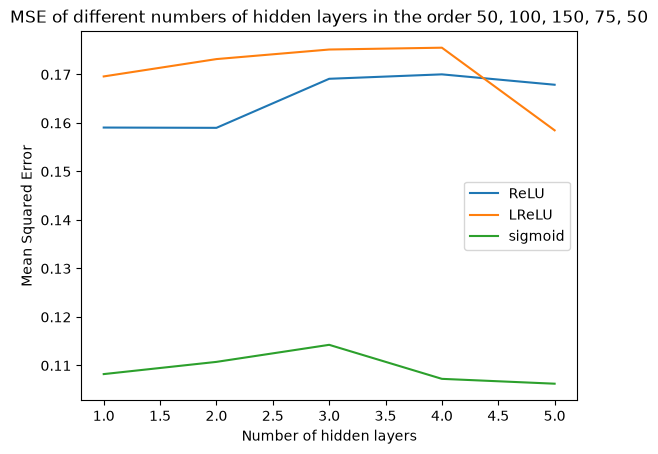

In [24]:

ReLU1_pred, ReLU2_pred, ReLU3_pred, ReLU4_pred, ReLU5_pred=ReLU1.predict(X_test), ReLU2.predict(X_test), ReLU3.predict(X_test), ReLU4.predict(X_test), ReLU5.predict(X_test)
LReLU1_pred, LReLU2_pred, LReLU3_pred, LReLU4_pred, LReLU5_pred=LReLU1.predict(X_test), LReLU2.predict(X_test), LReLU3.predict(X_test), LReLU4.predict(X_test), LReLU5.predict(X_test)
Sig1_pred, Sig2_pred, Sig3_pred, Sig4_pred, Sig5_pred=Sig1.predict(X_test), Sig2.predict(X_test), Sig3.predict(X_test), Sig4.predict(X_test), Sig5.predict(X_test)
R1_MSE,R2_MSE,R3_MSE,R4_MSE,R5_MSE=MSE_2(ReLU1_pred, y_test), MSE_2(ReLU2_pred, y_test), MSE_2(ReLU3_pred, y_test), MSE_2(ReLU4_pred, y_test), MSE_2(ReLU5_pred, y_test)
LR1_MSE,LR2_MSE,LR3_MSE,LR4_MSE,LR5_MSE=MSE_2(LReLU1_pred, y_test), MSE_2(LReLU2_pred, y_test), MSE_2(LReLU3_pred, y_test), MSE_2(LReLU4_pred, y_test), MSE_2(LReLU5_pred, y_test)
S1_MSE, S2_MSE, S3_MSE, S4_MSE, S5_MSE=MSE_2(Sig1_pred, y_test), MSE_2(Sig2_pred, y_test), MSE_2(Sig3_pred, y_test), MSE_2(Sig4_pred, y_test), MSE_2(Sig5_pred, y_test) 
ReLU_MSEs=[R1_MSE, R2_MSE, R3_MSE, R4_MSE, R5_MSE]
LReLU_MSEs=[LR1_MSE, LR2_MSE, LR3_MSE, LR4_MSE, LR5_MSE]
Sig_MSEs=[S1_MSE, S2_MSE, S3_MSE, S4_MSE, S5_MSE]
HLs=[1, 2, 3, 4, 5]
plt.title("MSE of different numbers of hidden layers in the order 50, 100, 150, 75, 50")
plt.plot(HLs, ReLU_MSEs, label="ReLU")
plt.plot(HLs, LReLU_MSEs, label="LReLU")
plt.plot(HLs, Sig_MSEs, label="sigmoid")
plt.legend()
plt.xlabel("Number of hidden layers")
plt.ylabel("Mean Squared Error")
plt.savefig("Plots/nhl_mse.pdf")
plt.show()




### Depth and width for each activation (heat maps)

In [ ]:
# 5-fold CV MSE on the training data, Adam, 500 epochs, for 1-5 hidden layers of 5-100 nodes
layers_c = [1, 2, 3, 4, 5]
nodes_c = [5, 10, 25, 50, 100]
acts_c = ["sigmoid", "relu", "lrelu"]
mse_c = {}
for act in acts_c:
    mse_c[act] = np.zeros((len(layers_c), len(nodes_c)))
    for i, L in enumerate(layers_c):
        for j, nodes in enumerate(nodes_c):
            net = NeuralNetRegressor(hidden=(nodes,) * L, activation=act, epochs=500, gamma=0.01, optimizer="adam")
            mse_c[act][i, j] = -np.mean(cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1))
    i_c, j_c = np.unravel_index(np.nanargmin(mse_c[act]), mse_c[act].shape)
    print(act, "best:", layers_c[i_c], "layers of", nodes_c[j_c], "nodes, CV MSE", mse_c[act][i_c, j_c])

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, act in zip(ax, acts_c):
    plot_heatmap(a, mse_c[act], nodes_c, layers_c, "nodes per hidden layer", "hidden layers", f"{act}: CV MSE", log=True)
plt.tight_layout()
plt.savefig("Plots/c_depth_width.pdf")
plt.show()

### Overfitting: training and test MSE as the number of nodes and layers grows

In [ ]:
# Trained for 3000 epochs (no early stopping) so that the bigger networks can overfit
nodes_of = [2, 5, 10, 25, 50, 100, 200]
layers_of = [1, 2, 3, 4, 5, 6]
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for act in acts_c:
    tr_n, te_n, tr_l, te_l = [], [], [], []
    for nodes in nodes_of:
        m = NeuralNetRegressor(hidden=(nodes,), activation=act, epochs=3000, gamma=0.01, optimizer="adam").fit(X, y)
        tr_n.append(MSE_2(m.predict(X), y))
        te_n.append(MSE_2(m.predict(X_test), y_test))
    for L in layers_of:
        m = NeuralNetRegressor(hidden=(50,) * L, activation=act, epochs=3000, gamma=0.01, optimizer="adam").fit(X, y)
        tr_l.append(MSE_2(m.predict(X), y))
        te_l.append(MSE_2(m.predict(X_test), y_test))
    ax[0].plot(nodes_of, te_n, "o-", label=f"{act} test")
    ax[0].plot(nodes_of, tr_n, "s--", label=f"{act} train")
    ax[1].plot(layers_of, te_l, "o-", label=f"{act} test")
    ax[1].plot(layers_of, tr_l, "s--", label=f"{act} train")
ax[0].set(xscale="log", yscale="log", xlabel="nodes (one hidden layer)", ylabel="MSE")
ax[1].set(yscale="log", xlabel="hidden layers of 50 nodes")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("Plots/c_overfitting.pdf")
plt.show()

## Task d

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
netl2 = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,50), gamma=0.03, activation="sigmoid", epochs=1000))
scoresl2 = -cross_val_score(netl2, X, y, cv=cv, scoring="neg_mean_squared_error")
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
param_grid = {"neuralnetregressor__gamma": [0.001, 0.01, 0.1, 0.5, 0.7],
            "neuralnetregressor__lmbd": [0.0, 1e-5, 1e-3, 1e-2, 1e-1]}
searchl2 = GridSearchCV(netl2, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1)
searchl2.fit(X, y)
resultsl2 = searchl2.cv_results_          # a dict of arrays, one entry per grid point


In [12]:

k = 5
gammas = param_grid["neuralnetregressor__gamma"]
lmbds = param_grid["neuralnetregressor__lmbd"]
msel2 = -resultsl2["mean_test_score"].reshape(5, 5)   # rows = gamma, columns = lambda
sel2 = resultsl2["std_test_score"].reshape(5, 5) / np.sqrt(k - 1)
trl2 = -resultsl2["mean_train_score"].reshape(5,5)
i_bestl2 = np.unravel_index(np.argmin(msel2), (5,5))
withinl2 = msel2 <= msel2[i_bestl2] + sel2[i_bestl2]
candl2 = [(j, i) for i in range(5) for j in range(5) if withinl2[i, j]]
j1l2, i1l2 = max(candl2, key=lambda t: (lmbds[t[0]], -gammas[t[1]]))
print("minimum:", searchl2.best_params_, f"CV MSE {msel2[i_bestl2]:.4f} +/- {sel2[i_bestl2]:.4f}")
print(f"1SE choice: gamma = {gammas[i1l2]}, lambda = {lmbds[j1l2]}, CV MSE {msel2[i1l2, j1l2]:.4f} +/- {sel2[i1l2, j1l2]:.4f}")


minimum: {'neuralnetregressor__gamma': 0.5, 'neuralnetregressor__lmbd': 0.001} CV MSE 0.0920 +/- 0.0110
1SE choice: gamma = 0.5, lambda = 0.001, CV MSE 0.0920 +/- 0.0110


In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
netl1 = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,50), gamma=0.03, activation="sigmoid", epochs=1000, L2=False))
scoresl1 = -cross_val_score(netl1, X, y, cv=cv, scoring="neg_mean_squared_error")
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
param_grid = {"neuralnetregressor__gamma": [0.001, 0.01, 0.1, 0.5, 0.7],
            "neuralnetregressor__lmbd": [0.0, 1e-5, 1e-3, 1e-2, 1e-1]}
searchl1 = GridSearchCV(netl1, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1)
searchl1.fit(X, y)
resultsl1 = searchl1.cv_results_          # a dict of arrays, one entry per grid point


In [10]:
k = 5
gammas = param_grid["neuralnetregressor__gamma"]
lmbds = param_grid["neuralnetregressor__lmbd"]
msel1 = -resultsl1["mean_test_score"].reshape(5, 5)   # rows = gamma, columns = lambda
sel1 = resultsl1["std_test_score"].reshape(5, 5) / np.sqrt(k - 1)
trl1 = -resultsl1["mean_train_score"].reshape(5,5)
i_bestl1 = np.unravel_index(np.argmin(msel1), (5,5))
withinl1 = msel1 <= msel1[i_bestl1] + sel1[i_bestl1]
candl1 = [(j, i) for i in range(5) for j in range(5) if withinl1[i, j]]
j1l1, i1l1 = max(candl1, key=lambda t: (lmbds[t[0]], -gammas[t[1]]))
print("minimum:", searchl1.best_params_, f"CV MSE {msel1[i_bestl1]:.4f} +/- {sel1[i_bestl1]:.4f}")
print(f"1SE choice: gamma = {gammas[i1l1]}, lambda = {lmbds[j1l1]}, CV MSE {msel1[i1l1, j1l1]:.4f} +/- {sel1[i1l1, j1l1]:.4f}")


minimum: {'neuralnetregressor__gamma': 0.5, 'neuralnetregressor__lmbd': 0.001} CV MSE 0.0807 +/- 0.0208
1SE choice: gamma = 0.5, lambda = 0.001, CV MSE 0.0807 +/- 0.0208


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_heatmap(ax[0], msel2, lmbds, gammas, r"$\lambda$", r"$\gamma$", "L2, hidden (50, 50): CV MSE", log=True)
plot_heatmap(ax[1], msel1, lmbds, gammas, r"$\lambda$", r"$\gamma$", "L1, hidden (50, 50): CV MSE", log=True)
plt.tight_layout()
plt.savefig("Plots/d_gamma_lambda.pdf")
plt.show()

### Architecture and $\lambda$ at the best learning rate

In [ ]:
hiddens_d = [(10,), (50,), (100,), (10, 10), (50, 50), (100, 100)]
param_grid_arch = {"neuralnetregressor__hidden": hiddens_d, "neuralnetregressor__lmbd": lmbds}
searchl2_arch = GridSearchCV(clone(netl2).set_params(neuralnetregressor__gamma=searchl2.best_params_["neuralnetregressor__gamma"]),
                             param_grid_arch, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1).fit(X, y)
searchl1_arch = GridSearchCV(clone(netl1).set_params(neuralnetregressor__gamma=searchl1.best_params_["neuralnetregressor__gamma"]),
                             param_grid_arch, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1).fit(X, y)
msel2_arch = -searchl2_arch.cv_results_["mean_test_score"].reshape(len(hiddens_d), len(lmbds))   # rows = hidden
msel1_arch = -searchl1_arch.cv_results_["mean_test_score"].reshape(len(hiddens_d), len(lmbds))
print("L2 best:", searchl2_arch.best_params_, "CV MSE", -searchl2_arch.best_score_)
print("L1 best:", searchl1_arch.best_params_, "CV MSE", -searchl1_arch.best_score_)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_heatmap(ax[0], msel2_arch, lmbds, [str(h) for h in hiddens_d], r"$\lambda$", "hidden layers", "L2: CV MSE", log=True)
plot_heatmap(ax[1], msel1_arch, lmbds, [str(h) for h in hiddens_d], r"$\lambda$", "hidden layers", "L1: CV MSE", log=True)
plt.tight_layout()
plt.savefig("Plots/d_arch_lambda.pdf")
plt.show()

### Comparison with Ridge and Lasso from project 1

In [ ]:
# Ridge exactly as in project 1 (Project1bb.ridge_analysis), Lasso with the project-1 convention
# (1/n)||y - X theta||^2 + lambda ||theta||_1, i.e. Scikit-Learn Lasso(alpha = lambda/2), same data and split.
degrees_p1 = np.arange(1, 16)
lams_p1 = np.logspace(-8, 0, 17)
ridge = ridge_analysis(x_tr, x_te, y_tr, y_te, lams_p1, degrees_p1)
i_r, j_r = np.unravel_index(np.argmin(ridge["mse_te"]), ridge["mse_te"].shape)
print(f"Ridge (project 1): degree {degrees_p1[j_r]}, lambda {lams_p1[i_r]:.0e}, test MSE {ridge['mse_te'][i_r, j_r]:.5f}")

mse_lasso = np.zeros((len(lams_p1), len(degrees_p1)))
for i, lam in enumerate(lams_p1):
    for j, p in enumerate(degrees_p1):
        X_tr_p, X_te_p = design_matrix(x_tr, p), design_matrix(x_te, p)
        sc_p = Scaler().fit(X_tr_p, y_tr)
        lasso = Lasso(alpha=lam / 2, fit_intercept=False, max_iter=100000).fit(sc_p.transform_X(X_tr_p), y_tr - sc_p.y_mean)
        mse_lasso[i, j] = MSE(y_te, sc_p.transform_X(X_te_p) @ lasso.coef_ + sc_p.y_mean)
i_l, j_l = np.unravel_index(np.argmin(mse_lasso), mse_lasso.shape)
print(f"Lasso (project 1): degree {degrees_p1[j_l]}, lambda {lams_p1[i_l]:.0e}, test MSE {mse_lasso[i_l, j_l]:.5f}")

# The best L2 and L1 networks (chosen by CV above) on the same test set
modell2 = searchl2_arch.best_estimator_
modell1 = searchl1_arch.best_estimator_
print("NN with L2:", searchl2_arch.best_params_, "test MSE", MSE_2(modell2.predict(X_test), y_test))
print("NN with L1:", searchl1_arch.best_params_, "test MSE", MSE_2(modell1.predict(X_test), y_test))
print("OLS, degree 14 (project 1); test MSE:", ols["mse_te"][0, 0])

## Task e

In [13]:
with np.load("mnist.npz") as data:
        xtr, ytr = data["x_train"], data["y_train"]
        xte, yte = data["x_test"], data["y_test"] # untouched until the end
print(xtr.shape, ytr.shape, xte.shape, yte.shape)
xtr = xtr.reshape(len(xtr), -1) / 255.0
xte = xte.reshape(len(xte), -1) / 255.0
    

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [ ]:
# Tune on a validation set split off the 60 000 training images; the test set is used once (next cell).
xfit, xval, yfit, yval = train_test_split(xtr, ytr, test_size=10000, stratify=ytr, random_state=2026)
model=NeuralNetClassifier(hidden=(50,), activation="sigmoid", epochs=1000, gamma=0.5)
fitted=model.fit(xfit, yfit)
print("validation accuracy:", accuracy_class(model.predict(xval), yval))

### Logistic regression (no hidden layers) = the baseline

In [ ]:
# Our network with hidden=() is multinomial logistic regression: only the softmax output layer.
# Tuned on the validation set, plain SGD, batches of 100.
gammas_log = [0.01, 0.03, 0.1, 0.3, 1.0]
acc_log = []
for g in gammas_log:
    logreg = NeuralNetClassifier(hidden=(), gamma=g, epochs=15, batch_size=100).fit(xfit, yfit)
    acc_log.append(accuracy_class(logreg.predict(xval), yval))
    print("Logistic regression, gamma =", g, "validation accuracy:", acc_log[-1])
gamma_log = gammas_log[np.argmax(acc_log)]

### Optimisers and learning rates

In [ ]:
# Hidden (100,), ReLU: plain SGD, RMSprop and Adam for several learning rates (validation accuracy).
opt_gammas = {"gd": [0.01, 0.03, 0.1, 0.3], "rmsprop": [1e-4, 3e-4, 1e-3, 3e-3], "adam": [1e-4, 3e-4, 1e-3, 3e-3]}
acc_opt = {}
for opt, gs in opt_gammas.items():
    acc_opt[opt] = []
    for g in gs:
        m = NeuralNetClassifier(hidden=(100,), activation="relu", gamma=g, epochs=15, batch_size=100, optimizer=opt).fit(xfit, yfit)
        acc_opt[opt].append(accuracy_class(m.predict(xval), yval))
        print(opt, "gamma =", g, "validation accuracy:", acc_opt[opt][-1])

plt.title("MNIST, hidden (100,), ReLU, 15 epochs")
plt.plot(opt_gammas["gd"], acc_opt["gd"], "o-", label="SGD")
plt.plot(opt_gammas["rmsprop"], acc_opt["rmsprop"], "o-", label="RMSprop")
plt.plot(opt_gammas["adam"], acc_opt["adam"], "o-", label="Adam")
plt.plot(gammas_log, acc_log, "s--", label="logistic regression, SGD")
plt.xscale("log")
plt.xlabel(r"$\gamma$")
plt.ylabel("validation accuracy")
plt.legend()
plt.savefig("Plots/e_optimisers.pdf")
plt.show()

### Heat maps: learning rate and $\lambda$, activation and architecture

In [ ]:
# gamma x lambda (L2), hidden (100,), ReLU, Adam
gammas_e = [1e-4, 3e-4, 1e-3, 3e-3]
lmbds_e = [0.0, 1e-6, 1e-5, 1e-4, 1e-3]
acc_gl = np.zeros((len(gammas_e), len(lmbds_e)))
for i, g in enumerate(gammas_e):
    for j, l in enumerate(lmbds_e):
        m = NeuralNetClassifier(hidden=(100,), activation="relu", gamma=g, lmbd=l, epochs=15, batch_size=100, optimizer="adam").fit(xfit, yfit)
        acc_gl[i, j] = accuracy_class(m.predict(xval), yval)
i_g, j_l = np.unravel_index(np.argmax(acc_gl), acc_gl.shape)
gamma_e, lmbd_e = gammas_e[i_g], lmbds_e[j_l]
print("best gamma =", gamma_e, "lambda =", lmbd_e, "validation accuracy:", acc_gl[i_g, j_l])

# activation x architecture at the best gamma and lambda
acts_e = ["sigmoid", "relu", "lrelu"]
hiddens_e = [(50,), (100,), (200,), (100, 100), (200, 200), (100, 100, 100)]
acc_ah = np.zeros((len(acts_e), len(hiddens_e)))
for i, a in enumerate(acts_e):
    for j, h in enumerate(hiddens_e):
        m = NeuralNetClassifier(hidden=h, activation=a, gamma=gamma_e, lmbd=lmbd_e, epochs=15, batch_size=100, optimizer="adam").fit(xfit, yfit)
        acc_ah[i, j] = accuracy_class(m.predict(xval), yval)
i_a, j_h = np.unravel_index(np.argmax(acc_ah), acc_ah.shape)
act_best, hidden_best = acts_e[i_a], hiddens_e[j_h]
print("best activation:", act_best, "hidden:", hidden_best, "validation accuracy:", acc_ah[i_a, j_h])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_heatmap(ax[0], acc_gl, lmbds_e, gammas_e, r"$\lambda$", r"$\gamma$", "Hidden (100,), ReLU, Adam", fmt="{:.4f}")
plot_heatmap(ax[1], acc_ah, [str(h) for h in hiddens_e], acts_e, "hidden layers", "activation",
             f"Adam, gamma = {gamma_e}, lambda = {lmbd_e}", fmt="{:.4f}")
plt.tight_layout()
plt.savefig("Plots/e_heatmaps.pdf")
plt.show()

In [ ]:
# Final evaluation of the chosen model on the untouched test set
pred=model.predict(xte)
acc=accuracy_class(pred, yte)
print("test accuracy:", acc)

### Best model and the baseline on the test set, confusion matrix

In [ ]:
# The chosen model and the baseline are refitted on all 60 000 training images; the test set is used once.
best = NeuralNetClassifier(hidden=hidden_best, activation=act_best, gamma=gamma_e, lmbd=lmbd_e, epochs=15,
                           batch_size=100, optimizer="adam").fit(xtr, ytr)
pred_best = best.predict(xte)
baseline = NeuralNetClassifier(hidden=(), gamma=gamma_log, epochs=15, batch_size=100).fit(xtr, ytr)
pred_base = baseline.predict(xte)
print("Own network", hidden_best, act_best, "test accuracy:", accuracy_class(pred_best, yte))
print("Own logistic regression (no hidden layers), test accuracy:", accuracy_class(pred_base, yte))
print("Guessing: 0.1")

In [ ]:
cm = confusion_matrix(yte, pred_best)
ConfusionMatrixDisplay(cm).plot(cmap="Blues", values_format="d")
plt.title(f"Own network {hidden_best}, {act_best}")
plt.savefig("Plots/e_confusion_matrix.pdf")
plt.show()
print(classification_report(yte, pred_best, digits=4))   # precision, recall and F1 per digit

### Comparison with Scikit-Learn

In [ ]:
# Same architecture and hyperparameters (sklearn has no leaky ReLU: relu is used instead).
# sklearn's alpha: penalty alpha/(2*batch) * ||W||^2 per batch, so alpha = 2*lambda*batch gives our lambda.
mlp = MLPClassifier(hidden_layer_sizes=hidden_best, activation="logistic" if act_best == "sigmoid" else "relu",
                    solver="adam", learning_rate_init=gamma_e, alpha=2 * lmbd_e * 100, batch_size=100,
                    max_iter=15, random_state=2026).fit(xtr, ytr)
print("Scikit-Learn MLPClassifier, test accuracy:", mlp.score(xte, yte))

# Logistic regression from Scikit-Learn, as in the project text (saga solver)
model_sk = LogisticRegression(solver="saga", max_iter=1000, random_state=42)
model_sk.fit(xtr, ytr)
print("Scikit-Learn LogisticRegression, test accuracy:", model_sk.score(xte, yte))